# Refining with `quick_fit` and checking fit quality

After a coarse `fit`, `EISData.quick_fit` refines a given `CircuitParameters` with a
single bounded least-squares solve. `blowing_bubbles.scripts.fit_quality` then gives
label-free quality metrics: it compares the circuit residual with the Lin-KK
(linear Kramers-Kronig) noise floor of the measurement and flags suspect fits.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from blowing_bubbles.classes import CircuitParameters, EISData

## Synthesize a noisy measurement and run a coarse fit

In [2]:
np.random.seed(42)

# Ground-truth R-CPE ladder: [Rs L (R_i C_i)_3]
true_params = CircuitParameters(
    resistance_source=10.0,
    inductance=1e-7,
    inductance_exponent=0.95,
    resistances=np.array([50.0, 20.0, 5.0]),
    capacitances=np.array([1e-4, 1e-3, 1e-2]),
    exponents=np.array([0.98, 0.95, 0.90]),
)

freqs = np.logspace(-2, 5, 100)
z_true = true_params.get_impedance(freqs)
noise = 0.1

data = pd.DataFrame(
    {
        "Freq (Hz)": freqs,
        "Zreal (Ohm)": z_true.real + np.random.normal(0, noise, freqs.size),
        "Zimag (Ohm)": z_true.imag + np.random.normal(0, noise, freqs.size),
    }
)
data.head()

,Freq (Hz),Zreal (Ohm),Zimag (Ohm)
0,0.010000,85.043517,-0.207331
1,0.011768,84.978994,-0.118759
2,0.013849,85.056389,-0.123674
3,0.016298,85.142516,-0.184444
4,0.019179,84.965146,-0.137615


In [3]:
eis = EISData(data)
coarse = eis.fit(n_restarts=30, rc_groups=3, seed=42)
print("coarse fit cost:", f"{coarse.cost:.4e}")

coarse fit cost: 3.0683e-03


## Fine-tune with `quick_fit`

`quick_fit` starts from the coarse parameters (the branch count is taken from them)
and runs one least-squares refinement. `complex_fit=True` also optimizes the CPE
exponents; the `*_bounds` arguments constrain the parameters.

In [4]:
refined = eis.quick_fit(
    initial_parameters=coarse.parameters,
    complex_fit=True,
    seed=42,
    sigma=0.25,
    resistance_source_bounds=(8.0, 12.0),
    resistance_branch_bounds=(1.0, 100.0),
    exponent_bounds=(0.85, 1.0),
)
print("coarse cost: ", f"{coarse.cost:.4e}")
print("refined cost:", f"{refined.cost:.4e}")
print(refined.parameters)

coarse cost:  3.0683e-03
refined cost: 3.0697e-03
  Resistance Source:        8.0000e+00
  Inductance:               2.4253e-06
  Inductance Exponent:      8.5000e-01
  Resistances:            [1.9969e+00 4.6927e+01 2.8093e+01]
  Capacitances:           [4.2627e-07 9.9914e-05 9.0418e-04]
  Exponents:              [8.8440e-01 9.8843e-01 9.0136e-01]
  Taus:                   [8.5122e-07 4.6887e-03 2.5401e-02]



## Label-free fit quality (Lin-KK)

`fit_quality(data, parameters)` returns the relative RMS residual of the circuit fit,
the Lin-KK residual (`rms_rel_kk`, the measurement noise floor), their ratio
(`kk_ratio`), and a `suspect` flag: a fit whose residual is more than
`kk_ratio_threshold` (default 3) times the Lin-KK floor has not captured the
spectrum.

In [5]:
from blowing_bubbles.scripts import fit_quality, lin_kk

quality = fit_quality(eis, refined.parameters)
for key, value in quality.items():
    print(f"{key:>16}: {value}")

     rms_rel_fit: 0.007835377648912534
      rms_rel_kk: 0.007531342349085808
        kk_ratio: 1.0403693373285083
            kk_M: 22
           kk_mu: 0.8125942537750865
     r_total_fit: 85.01669115558396
    r_total_lowf: 85.04351667175992
   r_total_ratio: 0.9996845671812997
         suspect: False


The Lin-KK test itself is available as `lin_kk(freq, z)` and returns the number of
RC elements `M`, the final $\mu$ criterion, and the relative RMS residual.

In [6]:
kk = lin_kk(eis.Freq, eis.Z)
print(
    f"Lin-KK: M = {kk['M']} elements, mu = {kk['mu']:.3f}, "
    f"rms_rel = {kk['rms_rel']:.4e}"
)

Lin-KK: M = 22 elements, mu = 0.813, rms_rel = 7.5313e-03


## Compare residuals

`FitResults.residuals_magnitude` holds $|\hat{Z}_k - Z_k|$ per frequency; plotting
it shows how `quick_fit` reduced the residual across the spectrum.

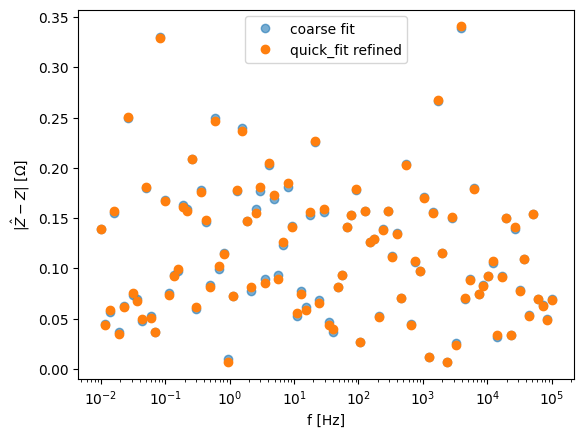

In [7]:
fig, ax = plt.subplots()
ax.semilogx(eis.Freq, coarse.residuals_magnitude, "o", alpha=0.6, label="coarse fit")
ax.semilogx(eis.Freq, refined.residuals_magnitude, "o", label="quick_fit refined")
ax.set_xlabel("f [Hz]")
ax.set_ylabel(r"|$\hat{Z} - Z$| [$\Omega$]")
ax.legend()
plt.show()